# Output reversals

Why does error rise a second time after a reversal, and how does connection search change recovery?

**Problem.** 108 independent standard normal inputs. Four target LTUs, each with four inputs, weights of ±1, and a zero threshold.
Two outputs each read all four LTUs with weights of ±1. The output noise has standard deviation 0.1.
Every 50,000 examples, all weights of the first output reverse. The second output never changes.

**Methods.** Both proposed methods have 64 hidden LTUs with 32 slots per unit.
Separate candidates connect a candidate only after enough evidence. With small initial steps, all slots are connections from the start.
Each control is a copy of a proposed method that stops all structure changes at the first reversal.
The ideal reference has the target's connections and learns its weights. All conditions use the same five seeds and examples.

**Shadow.** Each new hidden LTU gets a shadow, a fixed random sign on its first edge to an output.
While the weight of that edge is smaller than 1 in size, the backward pass uses the shadow in place of the weight.
Later edges have no shadow. A removed edge loses its shadow.

**Result.** After a reversal, LTUs whose shadow is on the reversed output lose their features, so error rises a second time.
Search connects the reversed output to LTUs whose shadow is on the fixed output or that have no shadow.
These LTUs keep their features, so later reversals recover fast. With connections fixed, the losses repeat at every reversal.

In the ideal reference, the shadow's output is the only difference between LTUs, so it causes the losses there.
No run tests by intervention that the new connections cause the faster recovery.


In [1]:
from phd.sandbox.unit_search.connection_slots import methods as m

assert m.jax.default_backend() == 'gpu'
%matplotlib inline


In [2]:
conditions = {'ideal': ('ideal', {}), 'candidates': ('candidates', {}),
              'candidates_frozen': ('candidates', {'frozen': True}),
              'single': ('single', {}), 'single_frozen': ('single', {'frozen': True})}
curves, records = m.run_reversals(conditions)


ideal: RMSE after the first reversal 0.376


candidates: RMSE after the first reversal 0.335


candidates_frozen: RMSE after the first reversal 0.512


single: RMSE after the first reversal 0.362


single_frozen: RMSE after the first reversal 0.379


118.5s for 5 seeds per condition


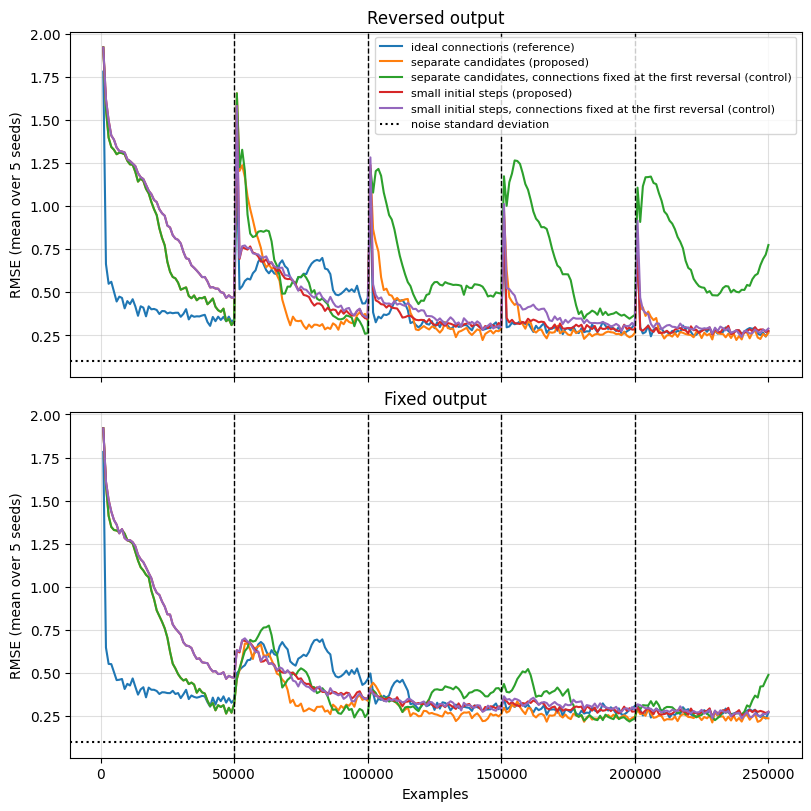

In [3]:
m.plot(curves, reversals=True)


Ideal reference, seed 2. LTUs 0 and 2 have their shadow on the reversed output (solid lines).
Agreement is +1 when an LTU matches its target LTU and −1 when it matches the negation.


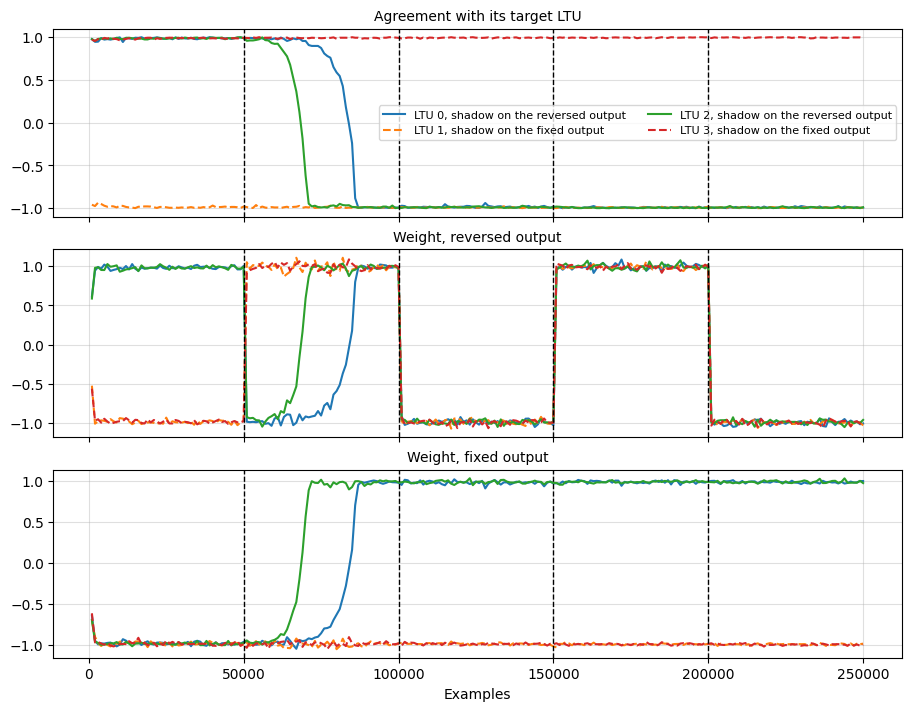

In [4]:
m.plot_units(records['ideal'], seed=2)


Lost features at each reversal, summed over seeds, by the output that holds the shadow.
A tracked LTU matches a target LTU, or its negation, on at least 95% of examples just before a reversal.
It loses its feature if this match falls below 75% before the next reversal.


In [5]:
m.shadow_summary(records)


ideal connections (reference)
  shadow on reversed output: 6/10  1/9  0/10  0/10
  shadow on fixed output:    0/10  0/10  0/10  0/10
separate candidates (proposed)
  shadow on reversed output: 18/19  9/9  3/4  1/1
  shadow on fixed output:    1/18  0/20  0/21  0/21
separate candidates, connections fixed at the first reversal (control)
  shadow on reversed output: 18/19  13/18  9/13  11/16
  shadow on fixed output:    0/18  0/17  0/18  0/18
small initial steps (proposed)
  shadow on reversed output: 9/15  2/3  2/3  0/0
  shadow on fixed output:    0/14  0/27  0/28  0/28
small initial steps, connections fixed at the first reversal (control)
  shadow on reversed output: 14/15  3/4  5/6  3/3
  shadow on fixed output:    0/14  0/26  0/27  0/27


Share of the reversed output's absolute weight on LTUs whose shadow is on that output.


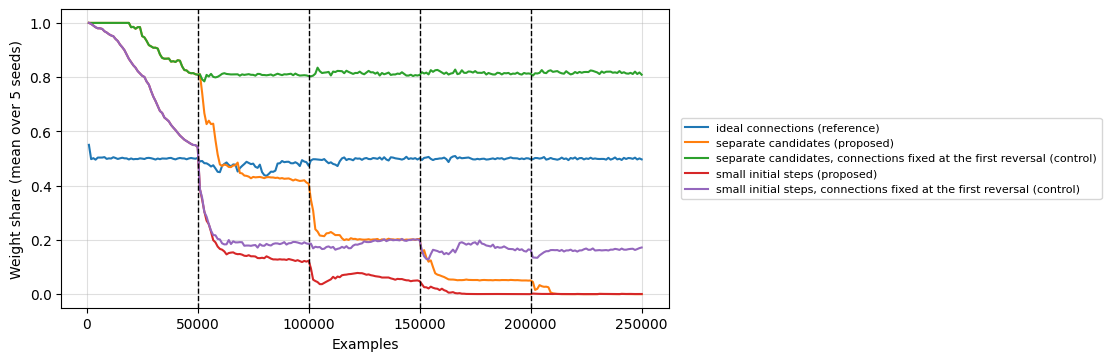

In [6]:
m.plot_share(records)
